# 13 · The campaign, the next experiments, and an agent

The same organizer as `11`–`12`, read as a **campaign** — inputs → results →
goals — and used to decide what to make next. Then the same operations as an
AI agent or a machine-learning model sees them.

Run `10`–`12` first: this opens `../OrgDemo/CuAu/cuau.json` with the WAXS
peak fits `12` kept.

In [1]:
import matplotlib.pyplot as plt

from pyDataOrg import Organizer, agent, optimize
from pyDataOrg.campaign import best_so_far, chronological, get_campaign, pareto_mask
from pyDataOrg.demo import demo_root
from pyDataOrg.viz import campaign as figures

org = Organizer(demo_root("CuAu", "cuau.json"))
org

<Organizer 'Cu-Au CO2RR library': 9 samples, all — ../../OrgDemo/CuAu/cuau.json>

## The campaign

A `Campaign` names about twenty numbers out of the hundreds of recorded fields.
A project package registers its own; the demo's is built in.

In [2]:
spec = get_campaign("CuAu-CO2RR")
frame = spec.table(org)                      # one row per sample, kept results joined in
frame[["sample", "x_Au", "q111", "j_CO", "FE_CO", "FE_H2"]].round(3)

,sample,x_Au,q111,j_CO,FE_CO,FE_H2
0,CuAu01,0.00,3.010,0.77,2.3,44.7
1,CuAu02,0.10,2.972,1.71,5.4,48.3
2,CuAu03,0.25,2.917,5.02,17.9,62.5
3,CuAu04,0.40,2.864,10.74,44.0,44.5
4,CuAu05,0.55,2.812,14.58,70.1,24.8
5,CuAu06,0.70,2.763,14.21,82.6,16.2
6,CuAu07,0.85,2.715,11.77,86.6,13.3
7,CuAu08,1.00,2.669,8.76,87.6,12.4
8,CuAu09,0.50,NaN,NaN,NaN,NaN


In [3]:
goals = [spec.objective("j_CO"), spec.objective("FE_H2")]   # CO current up, hydrogen down
ranked = spec.rank(frame, goals)
ranked[["sample", "x_Au", "j_CO", "FE_H2", "score", "pareto"]].round(3)

,sample,x_Au,j_CO,FE_H2,score,pareto
5,CuAu06,0.70,14.21,16.2,0.949,True
6,CuAu07,0.85,11.77,13.3,0.889,True
4,CuAu05,0.55,14.58,24.8,0.876,True
7,CuAu08,1.00,8.76,12.4,0.789,True
3,CuAu04,0.40,10.74,44.5,0.541,False
0,CuAu01,0.00,0.77,44.7,0.178,False
1,CuAu02,0.10,1.71,48.3,0.176,False
2,CuAu03,0.25,5.02,62.5,0.154,False


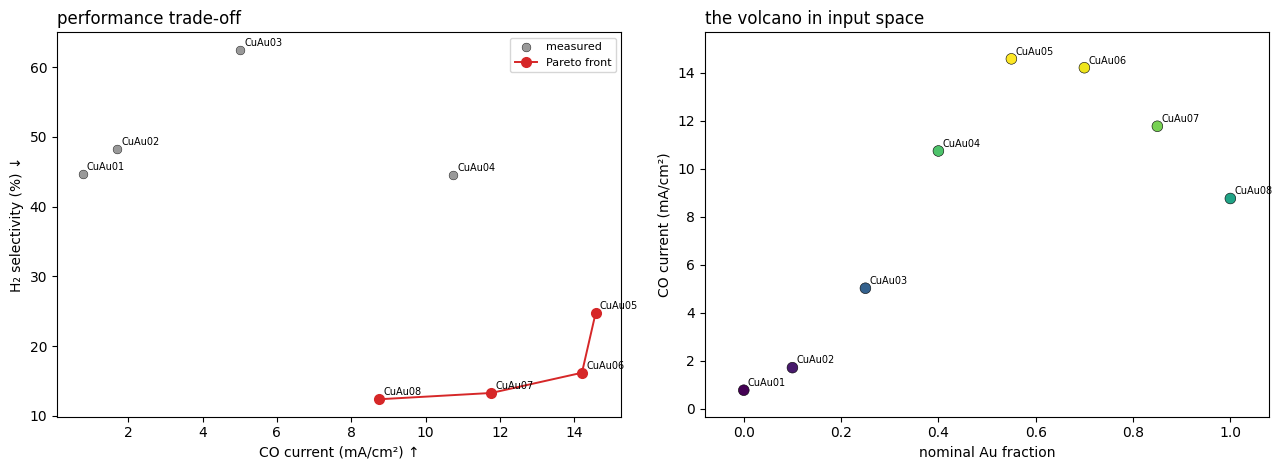

In [4]:
rows = frame[spec.comparable(frame, [g.name for g in goals])]
front = pareto_mask(rows[["j_CO", "FE_H2"]].to_numpy(float), [True, False])

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
figures.plot_pareto(rows, goals, ax=axes[0], front=front, labels=spec.labels)
figures.plot_design_map(rows, "x_Au", ax=axes[1], color="j_CO", labels=spec.labels,
                        title="the volcano in input space")
fig.tight_layout()

## What to make next

One Gaussian process per goal, and a batch of proposals that trades predicted
value against uncertainty. Check the model before trusting it.

In [5]:
plan = optimize.propose_for(spec, frame, objectives=goals, n=3)
plan.suggestions.round(3)

,proposal,x_Au,j_CO_pred,j_CO_sd,FE_H2_pred,FE_H2_sd
0,P1,0.74,13.674,0.092,15.193,3.408
1,P2,0.53,14.323,0.049,27.132,3.335
2,P3,0.96,9.536,0.139,12.424,3.425


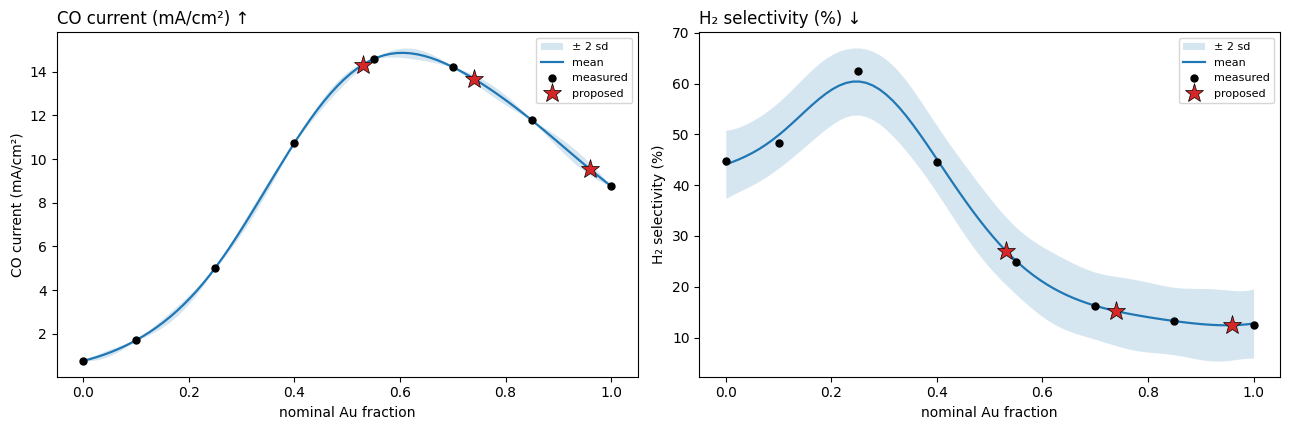

In [6]:
gx, _, mean, sd = plan.surface(80)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
for j, goal in enumerate(goals):
    figures.plot_surrogate_line(gx, mean[:, j], sd[:, j], ax=axes[j], points=plan.X[:, 0],
                                observed=plan.Y[:, j], proposals=plan.suggestions,
                                x="x_Au", name=goal.name, labels=spec.labels,
                                title=goal.label(spec.labels))
fig.tight_layout()

In [7]:
cv = optimize.cross_validate(frame, variables=spec.inputs, objectives=goals,
                             bounds=spec.bounds, rows=spec.comparable(frame, ["j_CO", "FE_H2"]))
print(cv.summary())

j_CO                 LOO error = 0.08 × its spread — predictive
FE_H2                LOO error = 0.35 × its spread — predictive


## Keeping up

When new records arrive, one call analyses exactly the new samples, with the
settings the kept results were made with.

In [8]:
org.status(org.kept_analyses())

,analysis,samples with data,kept,new
0,peak_fit@waxs1d,8,8,0
1,peak_fit@uvvis,8,8,0


## For an agent

The operations, with JSON schemas — as model tools, or over MCP
(`dataorg mcp ../OrgDemo/CuAu/cuau.json`). Read-only unless writes are allowed.

In [9]:
print(len(agent.tool_specs("anthropic")), "tools:", ", ".join(agent.list_operations(allow_writes=False)))
agent.call(org, "list_samples", query="`testing.performance.FE_CO_pct` > 60")

15 tools: describe_project, list_columns, list_samples, sample_table, sample_record, list_measurements, list_analyses, analysis_settings, run_analysis, batch_analysis, kept_results, analysis_status, list_campaigns, campaign_table, propose_next


['CuAu05', 'CuAu06', 'CuAu07', 'CuAu08']

In [10]:
agent.call(org, "save")                     # refused: no write access granted

{'error': 'save changes the organizer or writes files, and write access was not granted'}

## For a model of your own

The samples × features table — numeric, constant columns removed.

In [11]:
from pyDataOrg.export import feature_table

X = feature_table(org, campaign="CuAu-CO2RR")
X.round(3)

,x_Au,q111,FE_CO,j_CO,FE_H2
sample_id,,,,,
CuAu01,0.00,3.010,2.3,0.77,44.7
CuAu02,0.10,2.972,5.4,1.71,48.3
CuAu03,0.25,2.917,17.9,5.02,62.5
CuAu04,0.40,2.864,44.0,10.74,44.5
CuAu05,0.55,2.812,70.1,14.58,24.8
CuAu06,0.70,2.763,82.6,14.21,16.2
CuAu07,0.85,2.715,86.6,11.77,13.3
CuAu08,1.00,2.669,87.6,8.76,12.4
CuAu09,0.50,NaN,NaN,NaN,NaN
